In [3]:
pip install nibabel numpy scipy scikit-image trimesh pygltflib pyvista tqdm


Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip



   ---------------------------------------- 0.0/740.4 kB ? eta -:--:--
   ---------------------------------------- 740.4/740.4 kB 7.7 MB/s eta 0:00:00

   ------ --------------------------------- 1/6 [trimesh]
   ------ --------------------------------- 1/6 [trimesh]
   ------ --------------------------------- 1/6 [trimesh]
   ------ --------------------------------- 1/6 [trimesh]
   ------ --------------------------------- 1/6 [trimesh]
   ------ --------------------------------- 1/6 [trimesh]
   ------ --------------------------------- 1/6 [trimesh]
   ------ --------------------------------- 1/6 [trimesh]
   ------ --------------------------------- 1/6 [trimesh]
   ------ --------------------------------- 1/6 [trimesh]
   ------ --------------------------------- 1/6 [trimesh]
   ------ --------------------------------- 1/6 [trimesh]
   ------ --------------------------------- 1/6 [trimesh]
   ------ --------------------------------- 1/6 [trimesh]
   ------ -------------------------

Loading MRI volumes...
Loading masks...
Fusing MRI...
Computing Dice scores...
WT Dice: 0.8379
TC Dice: 0.4688
ET Dice: 0.0000
Extracting brain mesh...
Extracting tumor meshes...


Widget(value='<iframe src="http://localhost:64808/index.html?ui=P_0x1b5cba8b730_0&reconnect=auto" class="pyvis…

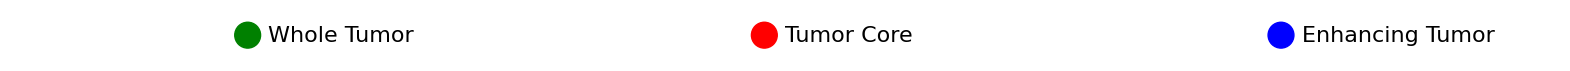

In [7]:
import os
import numpy as np
import nibabel as nib
from skimage import measure
from scipy.ndimage import gaussian_filter
import trimesh
import pyvista as pv

# -----------------------------
# CONFIG
# -----------------------------
DATA_DIR = "../data/BraTS2021_00000"
PRED_DIR = "E:/Radiomics/original/masks"
PATIENT_ID = "BraTS2021_00000"
OUTPUT_DIR = "../output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# -----------------------------
# UTILS
# -----------------------------
def load_nifti(path):
    nii = nib.load(path)
    return nii.get_fdata()

def normalize(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

def dice_score(pred, gt, label):
    pred_l = (pred == label)
    gt_l = (gt == label)
    inter = np.sum(pred_l & gt_l)
    union = np.sum(pred_l) + np.sum(gt_l)
    if union == 0:
        return 1.0
    return 2.0 * inter / union

# -----------------------------
# LOAD DATA
# -----------------------------
print("Loading MRI volumes...")
flair = load_nifti(f"{DATA_DIR}/{PATIENT_ID}_flair.nii.gz")
t1 = load_nifti(f"{DATA_DIR}/{PATIENT_ID}_t1.nii.gz")
t1ce = load_nifti(f"{DATA_DIR}/{PATIENT_ID}_t1ce.nii.gz")
t2 = load_nifti(f"{DATA_DIR}/{PATIENT_ID}_t2.nii.gz")

print("Loading masks...")
gt = load_nifti(f"{DATA_DIR}/{PATIENT_ID}_seg.nii.gz")
pred = load_nifti(f"{PRED_DIR}/{PATIENT_ID}_pred_seg.nii.gz")

# -----------------------------
# FUSE MRI
# -----------------------------
print("Fusing MRI...")
flair = normalize(flair)
t1 = normalize(t1)
t1ce = normalize(t1ce)
t2 = normalize(t2)

fused = (0.3 * flair + 0.2 * t1 + 0.3 * t1ce + 0.2 * t2)
fused = gaussian_filter(fused, sigma=1)

# -----------------------------
# DICE
# -----------------------------
print("Computing Dice scores...")
regions = {"WT": 1, "TC": 2, "ET": 3}
dice_scores = {}

for name, lab in regions.items():
    d = dice_score(pred, gt, lab)
    dice_scores[name] = d
    print(f"{name} Dice: {d:.4f}")

best_region = max(dice_scores, key=dice_scores.get)

# -----------------------------
# MESH EXTRACTION
# -----------------------------
print("Extracting brain mesh...")
brain_mask = fused > np.percentile(fused, 40)
v, f, _, _ = measure.marching_cubes(brain_mask, 0.5)
brain_mesh = trimesh.Trimesh(v, f, process=False)

print("Extracting tumor meshes...")
colors = {
    "WT": [255, 0, 0, 255],
    "TC": [0, 255, 0, 255],
    "ET": [0, 0, 255, 255]
}
tumor_meshes = {}
for name, lab in regions.items():
    mask = (pred == lab)
    if np.sum(mask) < 20: continue
    v_t, f_t, _, _ = measure.marching_cubes(mask, 0.5)
    m = trimesh.Trimesh(v_t, f_t, process=False)
    m.visual.face_colors = colors[name]
    tumor_meshes[name] = m

import pyvista as pv

# -----------------------------
# INTERACTIVE 3D VISUALIZATION
# -----------------------------

def show_interactive_brain(brain_mesh, tumor_meshes, dice_scores):
    # This backend enables interactive 3D within VS Code cells
    pv.set_jupyter_backend('client') 

    plotter = pv.Plotter(window_size=[800, 600])
    plotter.set_background("black")

    # 1. Add Brain (Transparent)
    brain_pv = pv.wrap(brain_mesh)
    plotter.add_mesh(brain_pv, color="silver", opacity=0.1, label="Brain")

    # 2. Add Tumor Regions
    pv_colors = {"WT": "red", "TC": "green", "ET": "blue"}
    for name, mesh in tumor_meshes.items():
        tumor_pv = pv.wrap(mesh)
        plotter.add_mesh(
            tumor_pv, 
            color=pv_colors[name], 
            label=f"{name} (Dice: {dice_scores[name]:.3f})"
        )

    # 3. Add the FIXED Legend
    # Legend is pinned to the camera view and won't rotate with the brain
    plotter.add_legend(
        bcolor=(0.1, 0.1, 0.1), 
        size=(0.2, 0.2)
    )

    # 4. Add Label
    plotter.add_text(f"Patient ID: {PATIENT_ID}", position='upper_left', font_size=10)

    # Display the rotatable element
    plotter.show()

# Execute
show_interactive_brain(brain_mesh, tumor_meshes, dice_scores)

import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_status_bar():
    # 1. Configuration
    items = [('green', 'Whole Tumor'), ('red', 'Tumor Core'), ('blue', 'Enhancing Tumor')]
    fig_width = 20
    fig_height = 0.8
    
    # 2. Create Figure and Axis
    # We use a specific figsize and set the background to white
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    
    # Define coordinate system: x from 0 to 30, y from 0 to 1
    ax.set_xlim(0, 30)
    ax.set_ylim(0, 1)
    
    # 4. Calculate Equal Spacing
    # We divide the width (10) into 3 equal parts.
    # The centers of these parts are at 1/6, 1/2, and 5/6 of the total width.
    positions = [5.0, 15.0, 25.0]
    circle_radius = 0.25 
    
    for i, (color, label) in enumerate(items):
        center_x = positions[i]
        
        # Draw Circle (slightly left of the center to balance the group)
        circle_x = center_x - 0.4
        circle = patches.Circle((circle_x, 0.5), circle_radius, color=color)
        ax.add_patch(circle)
        
        # Draw Text (directly to the right of the circle)
        ax.text(circle_x + 0.4, 0.5, label, ha='left', va='center', 
                fontsize=16, fontweight='light', color='black')

    # 5. Final Formatting
    ax.set_aspect('equal', adjustable='box') # Keeps circles round
    ax.axis('off') # Hides axis lines and ticks
    plt.show()

draw_status_bar()